# Practical 1C — CIFAR-10 Fully Connected Neural Network

Extracted from `1C.pdf`. Original displayed outputs omitted; executable Python code retained.

**Required local inputs:** `cifar-10.csv`

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

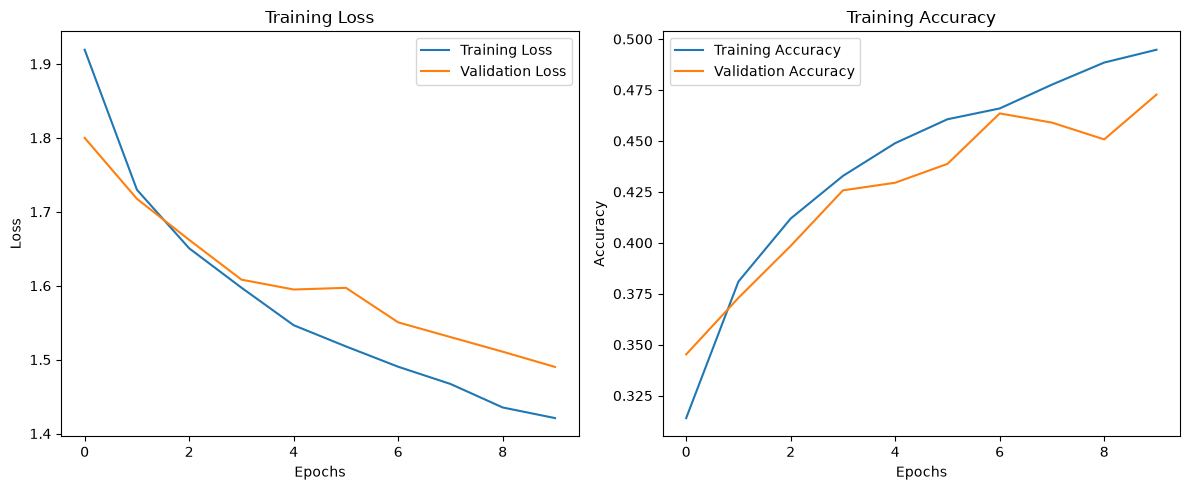

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.model_selection import train_test_split
data = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/FNN and CNN/CIFAR10/cifar-10.csv')
print(data.head())
print(data.shape)
X = data.drop('label', axis=1).values
y = data['label'].values
X = X.astype('float32') / 255.0
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = Sequential([
    Input(shape=(3072,)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(
    X_train, y_train,
    epochs=10, batch_size=64, validation_split=0.1
)
loss, accuracy = model.evaluate(X_test, y_test)
print('Test Loss:', loss)
print('Test Accuracy:', accuracy * 100, '%')
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()
